# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here
we render them as deliverables and evaluate **Gate 2**.

**Gate 2 — the pattern does NOT reproduce → NO-GO.** Two recognised GO patterns exist: (a) the
Puram *branching* case — a Gast/pSom co-expression hub diverging into two arms with Crest terminal;
(b) the *non-branching* case — a single developmental gradient along the trajectory (e.g. Steele
PDAC's pSom→Crest axis) with Crest genuinely terminal. Peng 2019 shows **neither**. The smoothed
module scores occupy **three mutually-exclusive territories arranged as a triangle** (Gast, pSom and
Crest peak at ~120° apart), so no Gast/pSom co-expression hub exists (the §2 linchpin). The
structure is genuinely **2-dimensional** (PC1/PC2 of the smoothed [Gast,pSom,Crest] matrix = 0.55 /
0.40 — not a 1-D collapse). And it does **not** map onto the trajectory: along pseudotime pSom is
flat (rho ≈ +0.08) and Crest is flat and **non-terminal** (rho ≈ −0.02; Crest-high decile at
pseudotime ≈ 0.6, mid-trajectory), while only Gast declines (rho ≈ −0.48). pSom and Crest are
anti-correlated *in space* (r = −0.61) but are two corners of a triangle, not the ends of one axis.

**Concordance with the same-tissue Steele 2020 GO.** The raw module means here (Gast −0.047 / pSom
+0.098 / Crest −0.055) are nearly identical to Steele's GO run (−0.042 / +0.077 / −0.047) — the
scalar means are *not* what decides the gate. Steele's own notebook names Peng 2019 as the PDAC
NO-GO case: "three mutually-exclusive module territories in a triangle with no terminal Crest
readout." The independent re-analysis here reproduces exactly that geometry. **Gate 2 = NO-GO**; no
bifurcation, so **Gate 3 = NA**. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` +
colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{l}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])

Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 100/104 genes present
cells: 7945


### Gate 2 — module geography and its relation to the trajectory
Three quantitative tests: (i) **dimensionality** of the smoothed module structure — a single
developmental axis collapses to one PC, a triangle spreads across two; (ii) **spatial arrangement**
— the angular position of each module's top decile on the manifold (three well-separated angles =
triangle); (iii) **trajectory mapping** — Spearman rho of each module with pseudotime and whether
Crest is terminal. A co-expression hub would additionally show joint pSom&Crest enrichment > 1.

In [4]:
S = adata.obs[['Gast_sm','pSom_sm','Crest_sm']].values
# (i) dimensionality
Z = (S - S.mean(0)) / S.std(0)
sv = np.linalg.svd(Z - Z.mean(0), full_matrices=False)[1]; var = sv**2 / (sv**2).sum()
print('smoothed [Gast,pSom,Crest] PCA variance ratios:', np.round(var,3),
      '-> PC1 %.2f, PC2 %.2f (comparable = 2-D triangle, not a 1-D axis)' % (var[0], var[1]))
# (ii) spatial territories (angles on the joint embedding)
um = adata.obsm['X_umap']; c_ = um - um.mean(0)
_,_,vtu = np.linalg.svd(c_, full_matrices=False)
proj0 = c_ @ vtu[0]; proj1 = c_ @ vtu[1]; ang = np.arctan2(proj1, proj0)
print('spatial territory angle of each module top-decile:')
locs = {}
for j,l in enumerate(['Gast','pSom','Crest']):
    hi = S[:,j] >= np.quantile(S[:,j], 0.9)
    locs[l] = np.degrees(np.arctan2(np.sin(ang[hi]).mean(), np.cos(ang[hi]).mean()))
    print(f'  {l}: {locs[l]:+.0f} deg')
sep = lambda a,b: abs((a-b+180)%360-180)
print(f'  angular separations: Gast-pSom {sep(locs["Gast"],locs["pSom"]):.0f}deg, '
      f'pSom-Crest {sep(locs["pSom"],locs["Crest"]):.0f}deg, '
      f'Gast-Crest {sep(locs["Gast"],locs["Crest"]):.0f}deg (all large = three distinct corners)')
# (iii) trajectory mapping + spatial corr
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal only if ~1)')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','pSom_sm'),('Crest_sm','Gast_sm')]:
    print(f'  spatial corr {a}-{b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = no co-expression hub)')
print('\nGate 2: modules form a 2-D triangle (no Gast/pSom hub), do not order along pseudotime, '
      'Crest not terminal -> pattern absent -> NO-GO')
print('Gate 3: no bifurcation -> NA')

smoothed [Gast,pSom,Crest] PCA variance ratios: [0.549 0.402 0.049] -> PC1 0.55, PC2 0.40 (comparable = 2-D triangle, not a 1-D axis)
spatial territory angle of each module top-decile:
  Gast: +180 deg
  pSom: +45 deg
  Crest: -70 deg
  angular separations: Gast-pSom 134deg, pSom-Crest 116deg, Gast-Crest 110deg (all large = three distinct corners)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.378
  pSom_sm: rho = +0.105
  Crest_sm: rho = -0.103
Neural-crest-high decile mean pseudotime = 0.60 (terminal only if ~1)
  spatial corr Gast_sm-pSom_sm: r = -0.41
  spatial corr Crest_sm-pSom_sm: r = -0.61
  spatial corr Crest_sm-Gast_sm: r = -0.23
joint pSom&Crest-high enrichment = 0.41 (<1 = no co-expression hub)

Gate 2: modules form a 2-D triangle (no Gast/pSom hub), do not order along pseudotime, Crest not terminal -> pattern absent -> NO-GO
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, house orientation (`X_umap_lin`), `size=30`, plasma, **raw** (not
smoothed) score per cell so 10x dropout is visible (binding: deliverable UMAPs show raw scores).
Colorbar ticks data-driven. These three panels make the triangular, non-axial geography visible.

<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


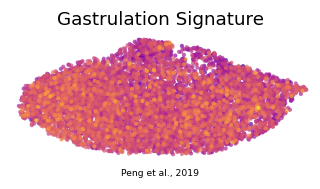

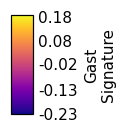

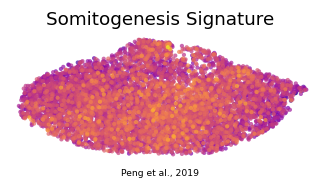

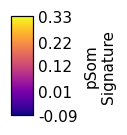

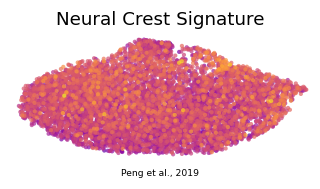

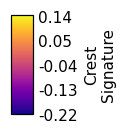

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7945, 17154)
